# Final Notebook

In [1]:
# Run this notebook with `notebooks/` as the working directory.
file_path = "./.final_ipynb/"
evaluation_data_path = "../data/test_alldata_EDA.csv"

## Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix, hstack

import pickle
from prettytable import PrettyTable

import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import confusion_matrix, f1_score, roc_curve, roc_auc_score

%matplotlib inline

## Loading Data

In [3]:
# Load the fitted preprocessing objects and selected-feature random forest.
with open(file_path + 'saved_dict.pkl', 'rb') as input_file:
    saved_dict = pickle.load(input_file)
with open(file_path + 'mode_dict.pkl', 'rb') as input_file:
    mode_dict = pickle.load(input_file)
with open(file_path + 'scaler.pkl', 'rb') as input_file:
    scaler = pickle.load(input_file)
with open(file_path + 'ohe_proto.pkl', 'rb') as input_file:
    ohe_proto = pickle.load(input_file)
with open(file_path + 'ohe_service.pkl', 'rb') as input_file:
    ohe_service = pickle.load(input_file)
with open(file_path + 'ohe_state.pkl', 'rb') as input_file:
    ohe_state = pickle.load(input_file)
with open(file_path + 'rf_clf_imp.pkl', 'rb') as input_file:
    best_model = pickle.load(input_file)
with open(file_path + 'final_train_meta.pkl', 'rb') as input_file:
    train_columns, _ = pickle.load(input_file)

feature_indices = np.asarray(saved_dict['imp_indices'], dtype=np.intp)
if best_model.n_features_in_ != len(feature_indices):
    raise ValueError("The saved feature indices do not match the selected-feature model.")
if feature_indices.size == 0 or feature_indices.min() < 0 or feature_indices.max() >= len(train_columns):
    raise ValueError("The saved selected-feature indices are outside the training feature schema.")

# Load the current held-out test split. Keep labels separate from prediction inputs.
evaluation_data = pd.read_csv(evaluation_data_path, keep_default_na=False)
if 'label' not in evaluation_data.columns:
    raise ValueError(f"Expected the binary 'label' column in {evaluation_data_path}.")
y_test = evaluation_data.pop('label').astype('int8')
x_test = evaluation_data.drop(columns=['attack_cat'], errors='ignore')
print("Loaded held-out raw rows:", x_test.shape[0])

Loaded held-out raw rows: 15000


## Utility Functions

In [4]:
def clean_data(data):
    """Apply the training pipeline's fill, category, and binary-value cleanup."""
    categorical_columns = set(saved_dict['cat_col'])
    for column in data.columns:
        if column not in mode_dict:
            raise ValueError(f"No training fill value is available for column {column!r}.")
        values = data[column].replace(r'^\s*$', np.nan, regex=True)
        values = values.replace('-', 'None').fillna(mode_dict[column])
        if column not in categorical_columns:
            values = pd.to_numeric(values, errors='raise')
        if column in saved_dict['binary_col']:
            values = np.where(values > 1, mode_dict[column], values)
        data[column] = values
    return data


def apply_log1p(data):
    """Replace the fitted skewed numeric inputs with their log1p versions."""
    for column in saved_dict['log1p_col']:
        data[column + '_log1p'] = np.log1p(data[column])
        data.drop(columns=[column], inplace=True)
    return data


def standardize(data):
    """Apply the scaler fitted on training data."""
    data[saved_dict['num_col']] = scaler.transform(data[saved_dict['num_col']])
    return data


def csr_to_sparse_dataframe(matrix, columns, index):
    """Create a labeled pandas sparse DataFrame without expanding implicit zeros."""
    if matrix.shape[1] != len(columns):
        raise ValueError("The number of column names must match the sparse matrix width.")
    if matrix.shape[0] != len(index):
        raise ValueError("The DataFrame index length must match the sparse matrix height.")
    return pd.DataFrame.sparse.from_spmatrix(matrix, columns=columns, index=index)


def prepare_model_matrix(raw_data):
    """Apply fitted preprocessing and return the selected features in CSR format."""
    if isinstance(raw_data, pd.Series):
        raw_data = raw_data.to_frame().T
    if not isinstance(raw_data, pd.DataFrame):
        raise TypeError("Prediction input must be a pandas DataFrame or a named Series.")

    data = raw_data.copy()
    data.drop(columns=['label', 'attack_cat'], errors='ignore', inplace=True)
    required_raw_columns = [column for column in saved_dict['columns'] if column != 'attack_cat']
    missing_columns = [column for column in required_raw_columns if column not in data.columns]
    if missing_columns:
        raise ValueError(f"Raw input is missing required UNSW-NB15 features: {missing_columns}")
    data = data.loc[:, required_raw_columns].copy()

    data['network_bytes'] = data['dbytes'] + data['sbytes']
    columns_to_drop = saved_dict['to_drop'] + saved_dict['corr_col']
    data.drop(columns=[column for column in columns_to_drop if column in data.columns], inplace=True)

    data = clean_data(data)
    # The feature-engineering test path maps the no-service marker to the trained 'others' category.
    data['service'] = data['service'].replace('None', 'others')
    data = apply_log1p(data)
    data = standardize(data)

    encoded_pieces = []
    for column, encoder in [('proto', ohe_proto), ('service', ohe_service), ('state', ohe_state)]:
        encoded = encoder.transform(data[column].to_numpy(dtype=object).reshape(-1, 1))
        encoded_pieces.append(csr_to_sparse_dataframe(
            encoded,
            [column + '_' + str(category) for category in encoder.categories_[0]],
            index=data.index,
        ))
    data.drop(columns=['proto', 'service', 'state'], inplace=True)
    data = pd.concat([data] + encoded_pieces, axis=1)

    missing_model_columns = [column for column in train_columns if column not in data.columns]
    extra_model_columns = [column for column in data.columns if column not in train_columns]
    if missing_model_columns or extra_model_columns:
        raise ValueError(
            f"Preprocessed feature schema differs from training. Missing={missing_model_columns}; "
            f"extra={extra_model_columns}"
        )
    data = data.loc[:, train_columns]

    numeric_columns = saved_dict['num_col']
    encoded_columns = [column for column in train_columns if column not in numeric_columns]
    if list(data.columns[:len(numeric_columns)]) != numeric_columns:
        raise ValueError("Numeric feature order differs from the saved training schema.")
    dense = csr_matrix(data[numeric_columns].to_numpy(dtype=np.float64, copy=False))
    encoded = data[encoded_columns].sparse.to_coo().tocsr()
    full_matrix = hstack((dense, encoded), format='csr', dtype=np.float64)
    if full_matrix.shape[1] != len(train_columns):
        raise ValueError("Preprocessed matrix width differs from the saved training schema.")
    selected_matrix = full_matrix[:, feature_indices].tocsr()
    if selected_matrix.shape[1] != best_model.n_features_in_:
        raise ValueError("Selected prediction matrix width differs from the saved model.")
    return selected_matrix


def final_fun_1(raw_data):
    """Predict normal (0) or attack (1) for one or more raw UNSW-NB15 records."""
    return best_model.predict(prepare_model_matrix(raw_data))

In [5]:
def final_fun_2(raw_data, y_true):
    """Evaluate predictions, using continuous probabilities for standard ROC-AUC."""
    y_true = np.asarray(y_true)
    x_model = prepare_model_matrix(raw_data)
    y_pred = best_model.predict(x_model)
    positive_class_index = np.flatnonzero(best_model.classes_ == 1)
    if positive_class_index.size != 1:
        raise ValueError("The saved estimator must contain positive class 1.")
    y_score = best_model.predict_proba(x_model)[:, positive_class_index[0]]

    C = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = C.ravel()
    fpr, tpr, _ = roc_curve(y_true, y_score, pos_label=1)
    y_auc = roc_auc_score(y_true, y_score)
    y_f1 = f1_score(y_true, y_pred)
    false_positive_rate = fp / (fp + tn) if fp + tn else 0.0
    false_negative_rate = fn / (fn + tp) if fn + tp else 0.0
    y_far = (false_positive_rate + false_negative_rate) / 2

    P = np.divide(C, C.sum(axis=0, keepdims=True), out=np.zeros_like(C, dtype=float), where=C.sum(axis=0, keepdims=True) != 0)
    R = np.divide(C, C.sum(axis=1, keepdims=True), out=np.zeros_like(C, dtype=float), where=C.sum(axis=1, keepdims=True) != 0)

    table = PrettyTable()
    table.field_names = ['ROC-AUC', 'F1-score', 'Mean FPR/FNR']
    table.add_row([y_auc, y_f1, y_far])
    print(table)

    plt.figure(figsize=(12, 5))
    plt.plot(fpr, tpr, color='r', label=f"ROC-AUC: {y_auc:.4f}")
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.grid()
    plt.legend()
    plt.show()

    labels = ['normal', 'attack']
    plt.figure(figsize=(18, 5))
    for position, (matrix, title, cmap, fmt) in enumerate([
        (C, 'Confusion Matrix', 'Blues', 'd'),
        (P, 'Precision by Predicted Class', 'Greens', '.3f'),
        (R, 'Recall by True Class', 'BuPu', '.3f'),
    ], start=1):
        plt.subplot(1, 3, position)
        sns.heatmap(matrix, annot=True, cmap=cmap, fmt=fmt, xticklabels=labels, yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(title)
    plt.show()
    return y_auc, y_f1, y_far

In [6]:
# The sample rows in the prepared test CSV contain labels only for evaluation.
y_pred = final_fun_1(x_test.iloc[[0]])
print("prediction:", y_pred[0], "actual:", y_test.iloc[0])

prediction: 0 actual: 0


In [7]:
# Check a small batch while preserving one row per prediction.
y_pred = final_fun_1(x_test.iloc[90:100])
print("predicted:", y_pred)
print("actual:   ", y_test.iloc[90:100].to_numpy())

predicted: [0 0 0 0 0 1 1 0 0 0]
actual:    [0 0 0 0 0 1 1 0 0 0]


In [8]:
# Evaluate all 15,000 held-out rows through the same raw-input preprocessing path.
y_pred = final_fun_1(x_test)
print("Held-out F1:", f1_score(y_test.to_numpy(), y_pred))

Held-out F1: 0.9684428349715468


+--------------------+--------------------+----------------------+
|      ROC-AUC       |      F1-score      |     Mean FPR/FNR     |
+--------------------+--------------------+----------------------+
| 0.9995719759938793 | 0.9684428349715468 | 0.015544507312488052 |
+--------------------+--------------------+----------------------+


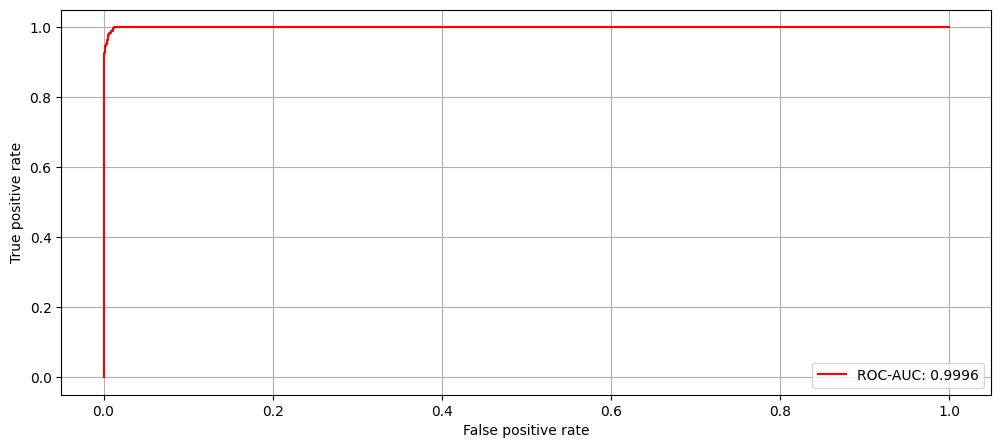

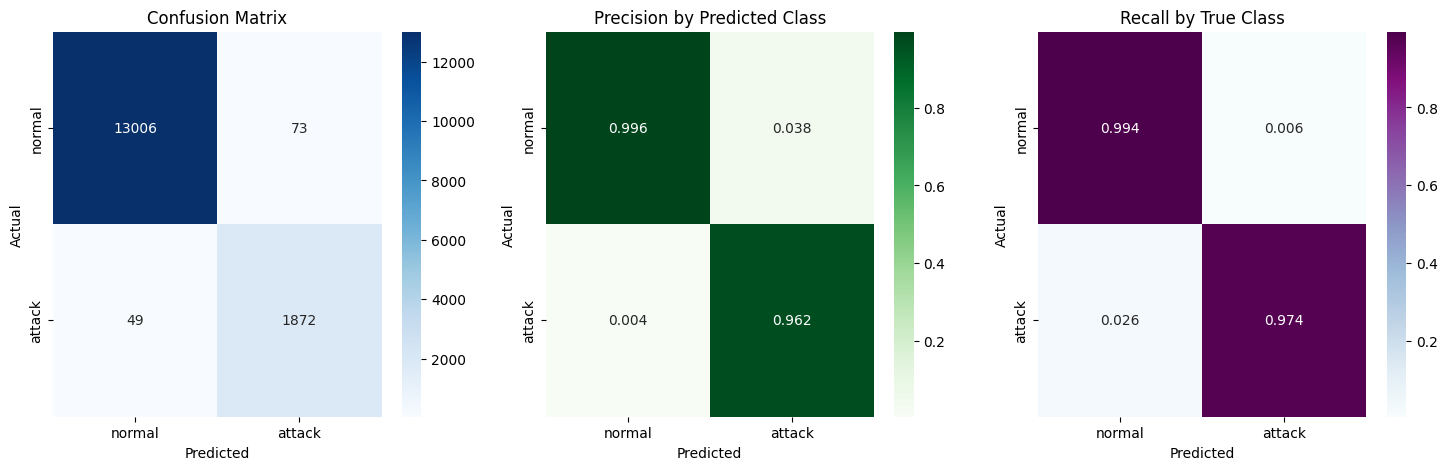

In [9]:
roc_auc, f1, mean_fpr_fnr = final_fun_2(x_test, y_test.to_numpy())

In [10]:
print("ROC-AUC:", roc_auc, "F1:", f1, "Mean FPR/FNR:", mean_fpr_fnr)

ROC-AUC: 0.9995719759938793 F1: 0.9684428349715468 Mean FPR/FNR: 0.015544507312488052
